<a href="https://colab.research.google.com/github/IntanLestari19/Tugas-ProbabilitasDanStatistika/blob/main/Tugas_Eksplorasi_Python/Code_Distribusi_Probabilitas_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementasi Python: Distribusi Probabilitas
Jalankan sel pertama (import library) lebih dulu, lalu sel lainnya berurutan. Komentar `# library ...` menandai baris yang memakai library tertentu.

In [ ]:
# import library bawaan Python
import math
# import library bawaan Python
import itertools
# import library bawaan Python
import random
# import library bawaan Python
import statistics
# import library bawaan Python (Counter)
from collections import Counter
# import library bawaan Python (Fraction)
from fractions import Fraction
# import library numpy: array dan bilangan acak
import numpy as np
# import library pandas: tabel data
import pandas as pd
# import library matplotlib: grafik
import matplotlib.pyplot as plt
# import library scipy.stats: distribusi dan uji statistik
from scipy import stats
# import library scikit-learn: model Naive Bayes
from sklearn.naive_bayes import MultinomialNB
# import library scikit-learn: pengubah teks menjadi angka
from sklearn.feature_extraction.text import CountVectorizer

rng = np.random.default_rng(1)   # library numpy: generator acak untuk simulasi

## 1. Distribusi Hipergeometrik
**Contoh 1: Memilih Server yang Dipertahankan dari Server Rusak dan Baik**

Sebuah pusat data memiliki 12 server, dan 2 di antaranya dalam keadaan rusak. Manajemen memutuskan mempertahankan 6 server dan memilihnya secara acak tanpa pengembalian.

f(x) untuk x = 0, 1, 2: [0.2273 0.5455 0.2273]
F(1) = 0.7727
E(X) = 1.0 | Var(X) = 0.4545


Simulasi f(x)  : [0.2275 0.5447 0.2278]
Simulasi E(X) = 1.0003 | Var(X) = 0.4553


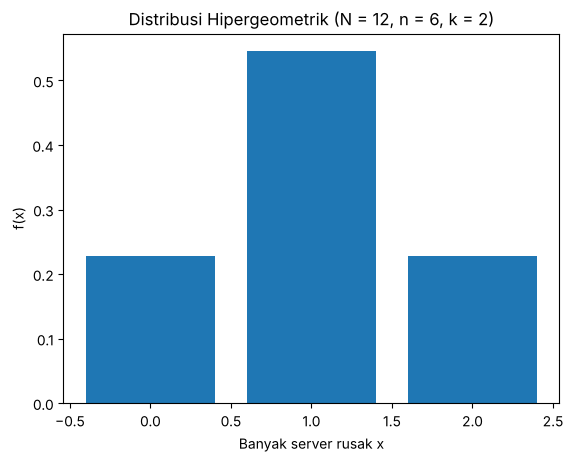

In [ ]:
# C.1 | Distribusi Hipergeometrik | Contoh 1: Memilih Server yang Dipertahankan dari Server Rusak dan Baik
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

# scipy: hypergeom(M = populasi N, n = banyak rusak k, N = ukuran sampel n)
# library scipy.stats: objek distribusi hypergeom
X = stats.hypergeom(M=12, n=2, N=6)
# library numpy: np.arange() operasi array
x = np.arange(0, 3)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("f(x) untuk x = 0, 1, 2:", X.pmf(x).round(4))
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("F(1) =", round(X.cdf(1), 4))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean(), "| Var(X) =", round(X.var(), 4))

# Simulasi: memilih 6 dari 12 server (2 rusak) tanpa pengembalian, 100.000 kali
# library numpy: np.array() operasi array
populasi = np.array([1] * 2 + [0] * 10)
# library numpy: rng.permutation() membangkitkan data acak
# library numpy: np.array() operasi array
# library numpy: .sum() menghitung dari array
rusak = np.array([rng.permutation(populasi)[:6].sum() for _ in range(100_000)])
# library numpy: np.bincount() operasi array
print("Simulasi f(x)  :", (np.bincount(rusak, minlength=3) / 100_000).round(4))
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(rusak.mean(), 4), "| Var(X) =", round(rusak.var(), 4))

# Grafik: PMF
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .pmf() menghitung peluang dari distribusi
plt.bar(x, X.pmf(x))
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Banyak server rusak x")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Hipergeometrik (N = 12, n = 6, k = 2)")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 2. Distribusi Binomial
**Contoh 1: Paket Hilang pada Pengiriman Data**

Sebuah sesi pengiriman data mengirim 10 paket. Setiap paket hilang dengan peluang 0,1 dan kehilangan antarpaket saling bebas.

P(X = 0)  = 0.3487
P(X >= 2) = 0.2639
F(1) = 0.7361
E(X) = 1.0 | Var(X) = 0.9
cs = 0.8433
Simulasi P(X = 0)  = 0.35001
Simulasi P(X >= 2) = 0.26507
Simulasi E(X) = 0.9992 | Var(X) = 0.8995


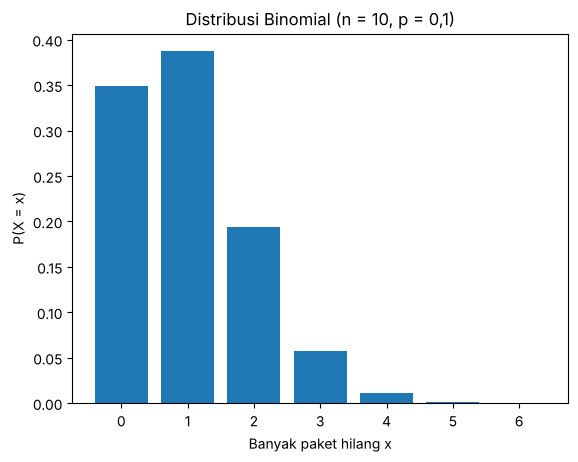

In [ ]:
# C.2 | Distribusi Binomial | Contoh 1: Paket Hilang pada Pengiriman Data
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

# library scipy.stats: objek distribusi binom
X = stats.binom(n=10, p=0.1)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("P(X = 0)  =", round(X.pmf(0), 4))
# library scipy.stats: .sf() menghitung peluang dari distribusi
print("P(X >= 2) =", round(X.sf(1), 4))        # sf(1) = 1 - P(X <= 1)
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("F(1) =", round(X.cdf(1), 4))                 # distribusi kumulatif
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean(), "| Var(X) =", round(X.var(), 4))
# library scipy.stats: .stats() menghitung nilai harapan, varians, atau skewness
print("cs =", round(float(X.stats(moments="s")), 4))     # koefisien skewness

# Simulasi: 100.000 sesi pengiriman
# library numpy: rng.binomial() membangkitkan data acak
hilang = rng.binomial(10, 0.1, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi P(X = 0)  =", (hilang == 0).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(X >= 2) =", (hilang >= 2).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(hilang.mean(), 4), "| Var(X) =", round(hilang.var(), 4))

# Grafik: PMF
# library numpy: np.arange() operasi array
x = np.arange(0, 7)
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .pmf() menghitung peluang dari distribusi
plt.bar(x, X.pmf(x))
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Banyak paket hilang x")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("P(X = x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Binomial (n = 10, p = 0,1)")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 3. Distribusi Geometrik
**Contoh 1: Percobaan Ulang Koneksi ke Server yang Sibuk**

Sebuah aplikasi mencoba terhubung ke server yang sibuk. Setiap percobaan koneksi berhasil dengan peluang 0,3 dan saling bebas. Aplikasi terus mencoba sampai koneksi berhasil.

f(3) = 0.147
F(5) = 0.83193
E(X) = 3.3333 | Var(X) = 7.7778
Simulasi f(3) = 0.14548
Simulasi F(5) = 0.8344
Simulasi E(X) = 3.3215 | Var(X) = 7.6442


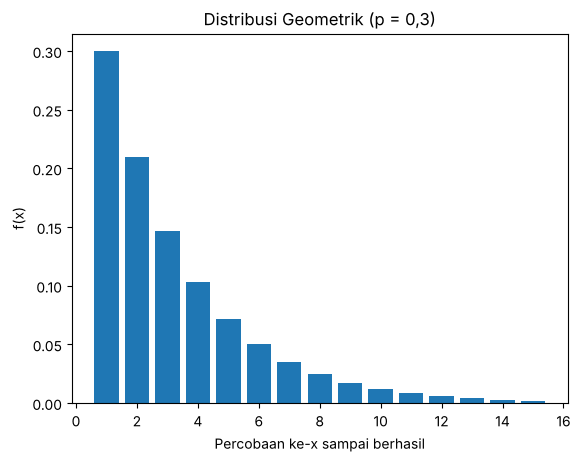

In [ ]:
# C.3 | Distribusi Geometrik | Contoh 1: Percobaan Ulang Koneksi ke Server yang Sibuk
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

p = 0.3
# library scipy.stats: objek distribusi geom
X = stats.geom(p)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("f(3) =", round(X.pmf(3), 4))
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("F(5) =", round(X.cdf(5), 5))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", round(X.mean(), 4), "| Var(X) =", round(X.var(), 4))

# Simulasi: 100.000 pengguna yang terus mencoba sampai berhasil
# library numpy: rng.geometric() membangkitkan data acak
percobaan = rng.geometric(p, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi f(3) =", (percobaan == 3).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi F(5) =", (percobaan <= 5).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(percobaan.mean(), 4), "| Var(X) =", round(percobaan.var(), 4))

# Grafik: PMF
# library numpy: np.arange() operasi array
x = np.arange(1, 16)
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .pmf() menghitung peluang dari distribusi
plt.bar(x, X.pmf(x))
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Percobaan ke-x sampai berhasil")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Geometrik (p = 0,3)")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 4. Distribusi Binomial Negatif
**Contoh 1: Penguji yang Mencari Tiga Bug**

Seorang penguji menjalankan test acak pada sebuah aplikasi. Setiap test menemukan bug baru dengan peluang 0,2 dan saling bebas. Pengujian dianggap cukup jika sudah ditemukan 3 bug.

f(10) = 0.0604
E(X) = 15.000000000000002 | Var(X) = 60.0
Simulasi f(10) = 0.06002
Simulasi E(X) = 15.0432 | Var(X) = 60.1729


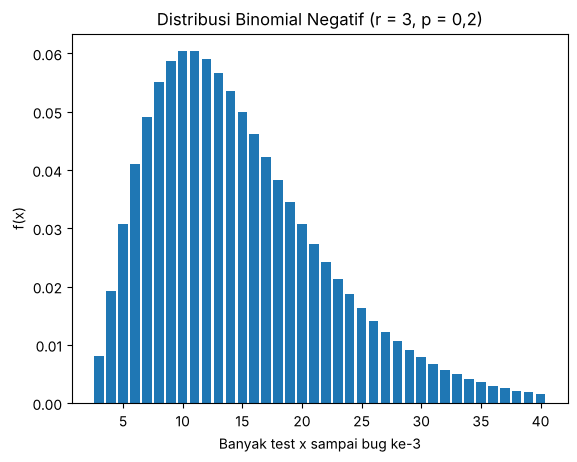

In [ ]:
# C.4 | Distribusi Binomial Negatif | Contoh 1: Penguji yang Mencari Tiga Bug
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

r, p = 3, 0.2
# scipy menghitung banyak kegagalan sebelum sukses ke-r, jadi x dikurangi r
# library scipy.stats: objek distribusi nbinom
X = stats.nbinom(r, p)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("f(10) =", round(X.pmf(10 - r), 4))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean() + r, "| Var(X) =", round(X.var(), 4))   # rata-rata ditambah r

# Simulasi: 100.000 penguji, banyak test = kegagalan + r
# library numpy: rng.negative_binomial() membangkitkan data acak
test = rng.negative_binomial(r, p, size=100_000) + r
# library numpy: .mean() menghitung dari array
print("Simulasi f(10) =", (test == 10).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(test.mean(), 4), "| Var(X) =", round(test.var(), 4))

# Grafik: PMF
# library numpy: np.arange() operasi array
x = np.arange(r, 41)
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .pmf() menghitung peluang dari distribusi
plt.bar(x, X.pmf(x - r))
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Banyak test x sampai bug ke-3")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Binomial Negatif (r = 3, p = 0,2)")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 5. Distribusi Poisson
**Contoh 1: Request per Detik pada Server API**

Sebuah server API menerima rata-rata 3 request per detik. Kedatangan request dianggap acak dan saling bebas.

P(X = 2)  = 0.224
P(X >= 1) = 0.9502
E(X) = 3.0 | Var(X) = 3.0
cs = 0.5774
Simulasi P(X = 2)  = 0.22421
Simulasi P(X >= 1) = 0.94999
Simulasi E(X) = 2.9951 | Var(X) = 3.0075


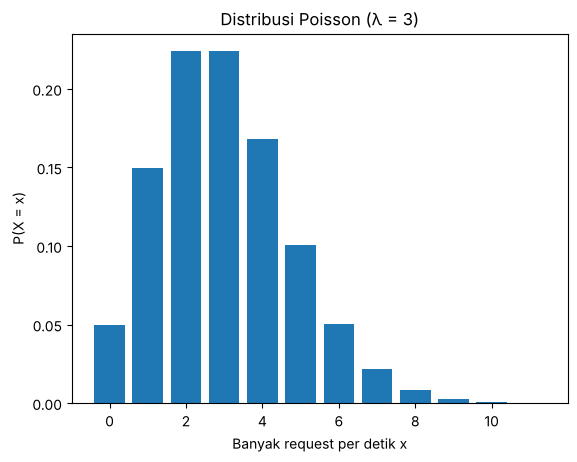

In [ ]:
# C.5 | Distribusi Poisson | Contoh 1: Request per Detik pada Server API
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

# library scipy.stats: objek distribusi poisson
X = stats.poisson(mu=3)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("P(X = 2)  =", round(X.pmf(2), 4))
# library scipy.stats: .sf() menghitung peluang dari distribusi
print("P(X >= 1) =", round(X.sf(0), 4))        # sf(0) = 1 - P(X = 0)
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean(), "| Var(X) =", X.var())
# library scipy.stats: .stats() menghitung nilai harapan, varians, atau skewness
print("cs =", round(float(X.stats(moments="s")), 4))

# Simulasi: 100.000 detik pengamatan
# library numpy: rng.poisson() membangkitkan data acak
req = rng.poisson(3, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi P(X = 2)  =", (req == 2).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(X >= 1) =", (req >= 1).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(req.mean(), 4), "| Var(X) =", round(req.var(), 4))

# Grafik: PMF
# library numpy: np.arange() operasi array
x = np.arange(0, 12)
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .pmf() menghitung peluang dari distribusi
plt.bar(x, X.pmf(x))
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Banyak request per detik x")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("P(X = x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Poisson (λ = 3)")
# library matplotlib: plt.show() untuk grafik
plt.show()


## 6. Distribusi Eksponensial
**Contoh 1: Jeda Antar Job pada Antrean CI**

Sebuah sistem CI menerima job build dengan laju rata-rata 0,5 job per menit, dengan kedatangan yang acak.

P(X > 3)  = 0.2231
P(X <= 1) = 0.3935
E(X) = 2.0 | Var(X) = 4.0
Simulasi P(X > 3)  = 0.222
Simulasi P(X <= 1) = 0.39289
Simulasi E(X) = 1.992 | Var(X) = 3.9333


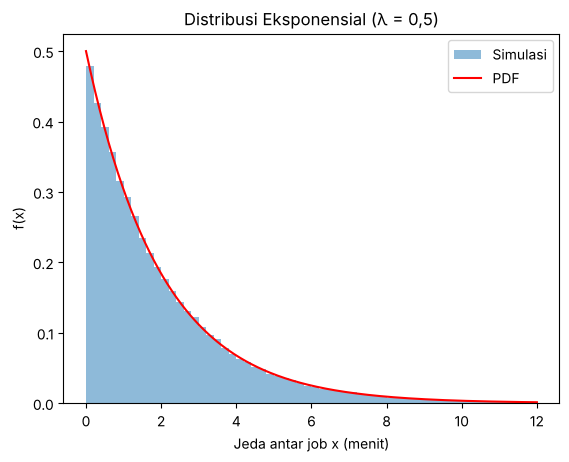

In [ ]:
# C.6 | Distribusi Eksponensial | Contoh 1: Jeda Antar Job pada Antrean CI
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

lam = 0.5
# library scipy.stats: objek distribusi expon
X = stats.expon(scale=1 / lam)                # scipy memakai scale = 1 / lambda
# library scipy.stats: .sf() menghitung peluang dari distribusi
print("P(X > 3)  =", round(X.sf(3), 4))
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("P(X <= 1) =", round(X.cdf(1), 4))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean(), "| Var(X) =", X.var())

# Simulasi: 100.000 jeda antar job
# library numpy: rng.exponential() membangkitkan data acak
jeda = rng.exponential(1 / lam, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi P(X > 3)  =", (jeda > 3).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(X <= 1) =", (jeda <= 1).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(jeda.mean(), 4), "| Var(X) =", round(jeda.var(), 4))

# Grafik: histogram simulasi dan PDF
# library numpy: np.linspace() operasi array
x = np.linspace(0, 12, 300)
# library matplotlib: plt.hist() untuk grafik
plt.hist(jeda, bins=60, range=(0, 12), density=True, alpha=0.5, label="Simulasi")
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, X.pdf(x), "r-", label="PDF")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Jeda antar job x (menit)")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Eksponensial (λ = 0,5)")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 7. Distribusi Gamma
**Contoh 1: Waktu Penyelesaian Lima Job Berurutan**

Sebuah runner CI memproses job satu per satu. Waktu satu job berdistribusi eksponensial dengan rata-rata 2 menit dan antarjob saling bebas. Tim ingin mengetahui total waktu untuk 5 job berurutan.

P(X <= 8) = 0.3712
Lewat Poisson: 1 - P(Y <= 4) = 0.3712
E(X) = 10.0 | Var(X) = 20.0
Simulasi P(X <= 8) = 0.37435
Simulasi E(X) = 9.9753 | Var(X) = 19.9898


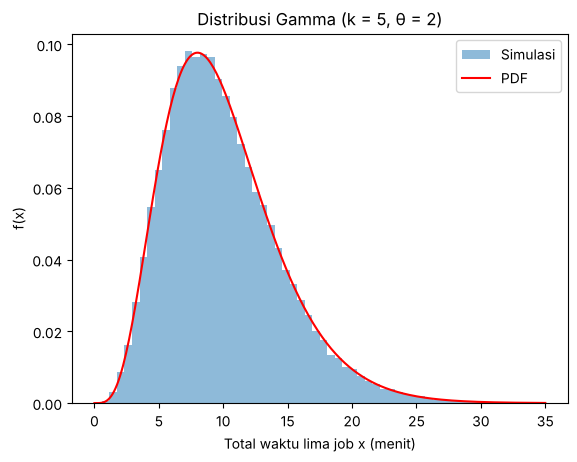

In [ ]:
# C.7 | Distribusi Gamma | Contoh 1: Waktu Penyelesaian Lima Job Berurutan
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

k, theta = 5, 2
# library scipy.stats: objek distribusi gamma
X = stats.gamma(a=k, scale=theta)
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("P(X <= 8) =", round(X.cdf(8), 4))
# library scipy.stats: objek distribusi poisson
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("Lewat Poisson: 1 - P(Y <= 4) =", round(1 - stats.poisson(4).cdf(4), 4))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean(), "| Var(X) =", X.var())

# Simulasi: jumlah lima waktu eksponensial, 100.000 kali
# library numpy: rng.exponential() membangkitkan data acak
# library numpy: .sum() menghitung dari array
total = rng.exponential(theta, size=(100_000, k)).sum(axis=1)
# library numpy: .mean() menghitung dari array
print("Simulasi P(X <= 8) =", (total <= 8).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", round(total.mean(), 4), "| Var(X) =", round(total.var(), 4))

# Grafik: histogram simulasi dan PDF
# library numpy: np.linspace() operasi array
x = np.linspace(0, 35, 300)
# library matplotlib: plt.hist() untuk grafik
plt.hist(total, bins=60, range=(0, 35), density=True, alpha=0.5, label="Simulasi")
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, X.pdf(x), "r-", label="PDF")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Total waktu lima job x (menit)")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Gamma (k = 5, θ = 2)")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 8. Distribusi Multinomial
**Contoh 1: Pengelompokan Email Masuk ke Tiga Kategori**

Sebuah layanan email mengelompokkan setiap email masuk ke salah satu dari tiga kategori, yaitu penting dengan peluang 0,2, promosi dengan peluang 0,5, dan spam dengan peluang 0,3. Dalam satu kelompok terdapat 10 email yang dikelompokkan secara bebas.

f(2, 5, 3) = 0.08505
E(X) = [2. 5. 3.]
Var(X) = [1.6 2.5 2.1]
Simulasi f(2, 5, 3) = 0.08529
Simulasi E(X) = [1.997 5.001 3.002]


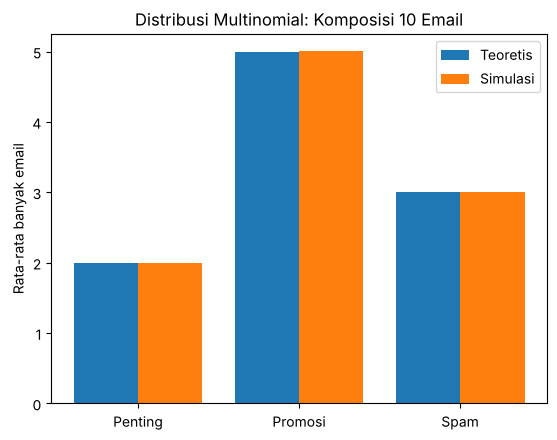

In [ ]:
# C.8 | Distribusi Multinomial | Contoh 1: Pengelompokan Email Masuk ke Tiga Kategori
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

n = 10
# library numpy: np.array() operasi array
p = np.array([0.2, 0.5, 0.3])                  # penting, promosi, spam
# library scipy.stats: objek distribusi multinomial
X = stats.multinomial(n, p)
# library scipy.stats: .pmf() menghitung peluang dari distribusi
print("f(2, 5, 3) =", round(X.pmf([2, 5, 3]), 5))
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
print("E(X) =", X.mean())
# library scipy.stats: .cov() menghitung nilai harapan, varians, atau skewness
print("Var(X) =", X.cov().diagonal().round(2))

# Simulasi: 100.000 kelompok berisi 10 email
# library numpy: rng.multinomial() membangkitkan data acak
sampel = rng.multinomial(n, p, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi f(2, 5, 3) =", (sampel == [2, 5, 3]).all(axis=1).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi E(X) =", sampel.mean(axis=0).round(3))

# Grafik: rata-rata teoretis dan simulasi
kategori = ["Penting", "Promosi", "Spam"]
# library numpy: np.arange() operasi array
x = np.arange(3)
# library matplotlib: plt.bar() untuk grafik
# library scipy.stats: .mean() menghitung nilai harapan, varians, atau skewness
plt.bar(x - 0.2, X.mean(), width=0.4, label="Teoretis")
# library numpy: .mean() menghitung dari array
# library matplotlib: plt.bar() untuk grafik
plt.bar(x + 0.2, sampel.mean(axis=0), width=0.4, label="Simulasi")
# library matplotlib: plt.xticks() untuk grafik
plt.xticks(x, kategori)
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("Rata-rata banyak email")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Multinomial: Komposisi 10 Email")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 9. Distribusi Normal
**Contoh 1: Waktu Respons API dan Target SLA**

Waktu respons sebuah API mendekati distribusi normal dengan rata-rata 200 ms dan simpangan baku 40 ms. Target layanan mensyaratkan request selesai dalam 300 ms.

P(X <= 300) = 0.9938
P(X > 260)  = 0.0668
x95 = 265.79 ms
z = 2.5 | cdf(z) = 0.9938 | pdf di x = 200 : 0.01
Simulasi P(X <= 300) = 0.99392
Simulasi P(X > 260)  = 0.06607
Simulasi x95 = 265.54 ms


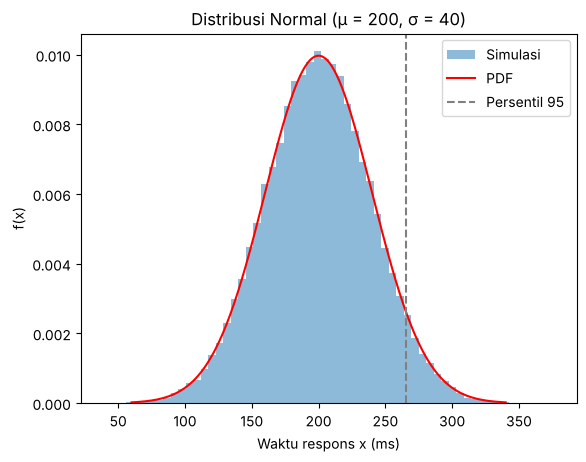

In [ ]:
# C.9 | Distribusi Normal | Contoh 1: Waktu Respons API dan Target SLA
# library numpy: default_rng() membuat generator bilangan acak
rng = np.random.default_rng(1)

# library scipy.stats: objek distribusi norm
X = stats.norm(loc=200, scale=40)
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("P(X <= 300) =", round(X.cdf(300), 4))
# library scipy.stats: .sf() menghitung peluang dari distribusi
print("P(X > 260)  =", round(X.sf(260), 4))
# library scipy.stats: .ppf() menghitung peluang dari distribusi
print("x95 =", round(X.ppf(0.95), 2), "ms")        # ppf = kebalikan dari cdf

# Distribusi normal standar: z = (x - mu) / sigma, lalu cdf tanpa parameter
z = (300 - 200) / 40
# library scipy.stats: objek distribusi norm
# library scipy.stats: .cdf() menghitung peluang dari distribusi
print("z =", z, "| cdf(z) =", round(stats.norm.cdf(z), 4), "| pdf di x = 200 :", round(X.pdf(200), 4))

# Simulasi: 100.000 request
# library numpy: rng.normal() membangkitkan data acak
waktu = rng.normal(200, 40, size=100_000)
# library numpy: .mean() menghitung dari array
print("Simulasi P(X <= 300) =", (waktu <= 300).mean())
# library numpy: .mean() menghitung dari array
print("Simulasi P(X > 260)  =", (waktu > 260).mean())
print("Simulasi x95 =", round(np.percentile(waktu, 95), 2), "ms")

# Grafik: histogram simulasi dan PDF
# library numpy: np.linspace() operasi array
x = np.linspace(60, 340, 300)
# library matplotlib: plt.hist() untuk grafik
plt.hist(waktu, bins=60, density=True, alpha=0.5, label="Simulasi")
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, X.pdf(x), "r-", label="PDF")
# library matplotlib: plt.axvline() untuk grafik
# library scipy.stats: .ppf() menghitung peluang dari distribusi
plt.axvline(X.ppf(0.95), color="gray", linestyle="--", label="Persentil 95")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Waktu respons x (ms)")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Normal (μ = 200, σ = 40)")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 10. Distribusi t
**Contoh 1: Uji Waktu Eksekusi Algoritma Baru terhadap Target**

Algoritma pencarian lama memerlukan waktu eksekusi rata-rata 125 ms. Algoritma baru dijalankan 8 kali dengan hasil 118, 121, 115, 124, 119, 120, 116, dan 123 ms. Tim memakai uji t pada taraf signifikansi 5% untuk menilai apakah rata-rata algoritma baru berbeda dari 125 ms.

x_bar = 119.5 | s = 3.1623 | galat baku = 1.118
t hitung = -4.9193 | t kritis = 2.3646
p-value = 0.0017 -> tolak H0
Selang kepercayaan 95% = 116.856 sampai 122.144
E(T) = 0.0 | Var(T) = 1.4
scipy ttest_1samp: t = -4.9193 | p-value = 0.0017


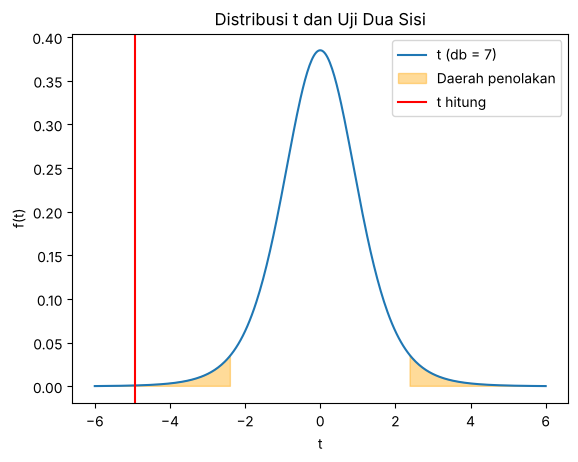

In [ ]:
# C.10 | Distribusi t | Contoh 1: Uji Waktu Eksekusi Algoritma Baru terhadap Target
data = [118, 121, 115, 124, 119, 120, 116, 123]
mu0, alpha = 125, 0.05
n = len(data)
db = n - 1

# library statistics: mean() menghitung rata-rata
rata = statistics.mean(data)
# library statistics: stdev() menghitung simpangan baku sampel
s = statistics.stdev(data)                      # simpangan baku sampel (pembagi n - 1)
# library math: sqrt() menghitung akar kuadrat
galat = s / math.sqrt(n)
t_hitung = (rata - mu0) / galat
# library scipy.stats: objek distribusi t
# library scipy.stats: .ppf() menghitung peluang dari distribusi
t_kritis = stats.t.ppf(1 - alpha / 2, db)
# library scipy.stats: objek distribusi t
# library scipy.stats: .cdf() menghitung peluang dari distribusi
p_value = 2 * stats.t.cdf(-abs(t_hitung), db)
# library scipy.stats: objek distribusi t
# library scipy.stats: .interval() menghitung peluang dari distribusi
batas = stats.t.interval(0.95, db, loc=rata, scale=galat)
print("x_bar =", rata, "| s =", round(s, 4), "| galat baku =", round(galat, 4))
print("t hitung =", round(t_hitung, 4), "| t kritis =", round(t_kritis, 4))
print("p-value =", round(p_value, 4), "->", "tolak H0" if abs(t_hitung) > t_kritis else "gagal tolak H0")
print("Selang kepercayaan 95% =", round(batas[0], 3), "sampai", round(batas[1], 3))
# library numpy: .mean() menghitung dari array
# library scipy.stats: objek distribusi t
print("E(T) =", stats.t.mean(db), "| Var(T) =", round(stats.t.var(db), 4))

# Pembanding: fungsi uji t satu sampel dari scipy
# library scipy.stats: ttest_1samp() fungsi uji statistik
hasil = stats.ttest_1samp(data, mu0)
print("scipy ttest_1samp: t =", round(hasil.statistic, 4), "| p-value =", round(hasil.pvalue, 4))

# Grafik: distribusi t, daerah penolakan, dan t hitung
# library numpy: np.linspace() operasi array
x = np.linspace(-6, 6, 400)
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: objek distribusi t
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, stats.t.pdf(x, db), label="t (db = 7)")
# library numpy: np.abs() operasi array
# library matplotlib: plt.fill_between() untuk grafik
# library scipy.stats: objek distribusi t
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.fill_between(x, stats.t.pdf(x, db), where=(np.abs(x) > t_kritis), color="orange", alpha=0.4, label="Daerah penolakan")
# library matplotlib: plt.axvline() untuk grafik
plt.axvline(t_hitung, color="red", label="t hitung")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("t")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(t)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi t dan Uji Dua Sisi")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 11. Distribusi Chi-Kuadrat
**Contoh 1: Uji Kemerataan Generator Angka Acak Dadu Virtual**

Sebuah game memakai generator angka acak untuk dadu virtual 6 sisi. Dari 1.200 lemparan, sisi 1 sampai 6 muncul masing-masing 180, 215, 195, 205, 190, dan 215 kali. Jika generator adil, tiap sisi diharapkan muncul 200 kali. Tim memakai uji chi-kuadrat pada taraf signifikansi 5%.

Chi-kuadrat hitung = 5.0 | db = 5
Nilai kritis = 11.0705
p-value = 0.4159 -> gagal tolak H0
E(X) = 5.0 | Var(X) = 10.0
scipy chisquare: statistik = 5.0 | p-value = 0.4159


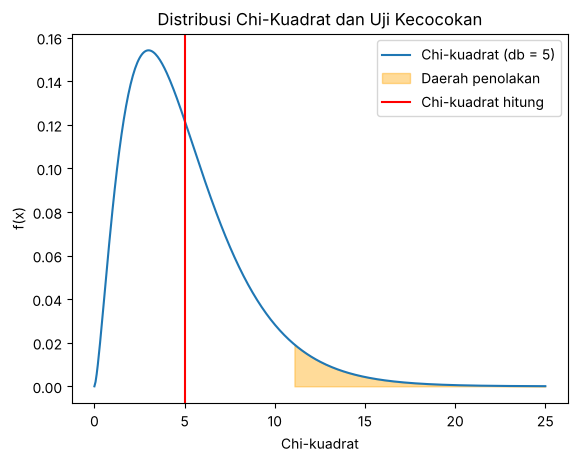

In [ ]:
# C.11 | Distribusi Chi-Kuadrat | Contoh 1: Uji Kemerataan Generator Angka Acak Dadu Virtual
# library numpy: np.array() operasi array
observasi = np.array([180, 215, 195, 205, 190, 215])
# library numpy: np.full() operasi array
# library numpy: .sum() menghitung dari array
harapan = np.full(6, observasi.sum() / 6)
db = len(observasi) - 1
alpha = 0.05

# library numpy: .sum() menghitung dari array
chi2_hitung = ((observasi - harapan) ** 2 / harapan).sum()
# library scipy.stats: objek distribusi chi2
# library scipy.stats: .ppf() menghitung peluang dari distribusi
chi2_kritis = stats.chi2.ppf(1 - alpha, db)
# library scipy.stats: objek distribusi chi2
# library scipy.stats: .sf() menghitung peluang dari distribusi
p_value = stats.chi2.sf(chi2_hitung, db)
print("Chi-kuadrat hitung =", chi2_hitung, "| db =", db)
print("Nilai kritis =", round(chi2_kritis, 4))
print("p-value =", round(p_value, 4), "->", "tolak H0" if chi2_hitung > chi2_kritis else "gagal tolak H0")
# library numpy: .mean() menghitung dari array
# library scipy.stats: objek distribusi chi2
print("E(X) =", stats.chi2.mean(db), "| Var(X) =", stats.chi2.var(db))

# Pembanding: fungsi uji kecocokan dari scipy
# library scipy.stats: chisquare() fungsi uji statistik
hasil = stats.chisquare(observasi)
print("scipy chisquare: statistik =", hasil.statistic, "| p-value =", round(hasil.pvalue, 4))

# Grafik: distribusi chi-kuadrat, daerah penolakan, dan nilai hitung
# library numpy: np.linspace() operasi array
x = np.linspace(0, 25, 400)
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: objek distribusi chi2
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, stats.chi2.pdf(x, db), label="Chi-kuadrat (db = 5)")
# library matplotlib: plt.fill_between() untuk grafik
# library scipy.stats: objek distribusi chi2
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.fill_between(x, stats.chi2.pdf(x, db), where=(x > chi2_kritis), color="orange", alpha=0.4, label="Daerah penolakan")
# library matplotlib: plt.axvline() untuk grafik
plt.axvline(chi2_hitung, color="red", label="Chi-kuadrat hitung")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("Chi-kuadrat")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi Chi-Kuadrat dan Uji Kecocokan")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()


## 12. Distribusi F
**Contoh 1: Perbandingan Waktu Respons Tiga Konfigurasi Server**

Tiga konfigurasi server A, B, dan C diuji dengan 5 pengukuran waktu respons dalam milidetik. Konfigurasi A menghasilkan 10, 12, 11, 9, dan 13. Konfigurasi B menghasilkan 14, 15, 13, 16, dan 12. Konfigurasi C menghasilkan 18, 17, 19, 16, dan 20. Tim memakai ANOVA satu arah pada taraf signifikansi 5% untuk menguji apakah rata-rata ketiganya sama.

JKA = 123.3333 | JKD = 30.0
KTA = 61.6667 | KTD = 2.5
F hitung = 24.6667 | F kritis = 3.8853
p-value = 5.61e-05 -> tolak H0
scipy f_oneway: F = 24.6667 | p-value = 5.61e-05


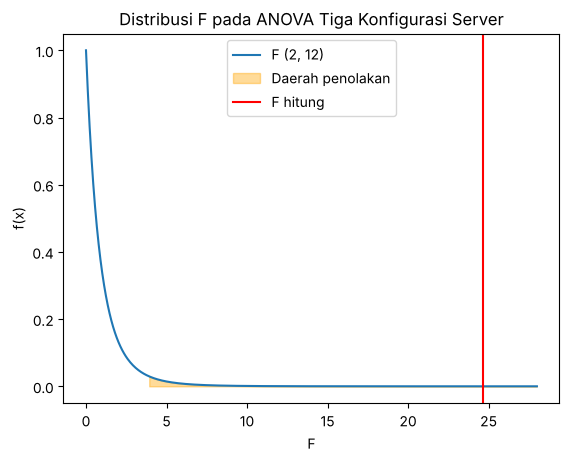

In [ ]:
# C.12 | Distribusi F | Contoh 1: Perbandingan Waktu Respons Tiga Konfigurasi Server
# library numpy: np.array() operasi array
A = np.array([10, 12, 11, 9, 13])
# library numpy: np.array() operasi array
B = np.array([14, 15, 13, 16, 12])
# library numpy: np.array() operasi array
C = np.array([18, 17, 19, 16, 20])
kelompok = [A, B, C]
k, n = len(kelompok), len(A)
N = k * n
alpha = 0.05

# library numpy: .mean() menghitung dari array
rata_kel = [g.mean() for g in kelompok]
# library numpy: np.concatenate() operasi array
# library numpy: .mean() menghitung dari array
rata_semua = np.concatenate(kelompok).mean()
JKA = sum(n * (m - rata_semua) ** 2 for m in rata_kel)
# library numpy: .mean() menghitung dari array
JKD = sum(((g - g.mean()) ** 2).sum() for g in kelompok)
db1, db2 = k - 1, N - k
KTA, KTD = JKA / db1, JKD / db2
F_hitung = KTA / KTD
# library scipy.stats: objek distribusi f
# library scipy.stats: .ppf() menghitung peluang dari distribusi
F_kritis = stats.f.ppf(1 - alpha, db1, db2)
# library scipy.stats: objek distribusi f
# library scipy.stats: .sf() menghitung peluang dari distribusi
p_value = stats.f.sf(F_hitung, db1, db2)
print("JKA =", round(JKA, 4), "| JKD =", JKD)
print("KTA =", round(KTA, 4), "| KTD =", KTD)
print("F hitung =", round(F_hitung, 4), "| F kritis =", round(F_kritis, 4))
print("p-value =", f"{p_value:.2e}", "->", "tolak H0" if F_hitung > F_kritis else "gagal tolak H0")

# Pembanding: fungsi ANOVA dari scipy
# library scipy.stats: f_oneway() fungsi uji statistik
hasil = stats.f_oneway(A, B, C)
print("scipy f_oneway: F =", round(hasil.statistic, 4), "| p-value =", f"{hasil.pvalue:.2e}")

# Grafik: distribusi F(2, 12), nilai kritis, dan F hitung
# library numpy: np.linspace() operasi array
x = np.linspace(0, 28, 500)
# library matplotlib: plt.plot() untuk grafik
# library scipy.stats: objek distribusi f
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.plot(x, stats.f.pdf(x, db1, db2), label="F (2, 12)")
# library matplotlib: plt.fill_between() untuk grafik
# library scipy.stats: objek distribusi f
# library scipy.stats: .pdf() menghitung peluang dari distribusi
plt.fill_between(x, stats.f.pdf(x, db1, db2), where=(x > F_kritis), color="orange", alpha=0.4, label="Daerah penolakan")
# library matplotlib: plt.axvline() untuk grafik
plt.axvline(F_hitung, color="red", label="F hitung")
# library matplotlib: plt.xlabel() untuk grafik
plt.xlabel("F")
# library matplotlib: plt.ylabel() untuk grafik
plt.ylabel("f(x)")
# library matplotlib: plt.title() untuk grafik
plt.title("Distribusi F pada ANOVA Tiga Konfigurasi Server")
# library matplotlib: plt.legend() untuk grafik
plt.legend()
# library matplotlib: plt.show() untuk grafik
plt.show()
